<div align="center">
    <img src="https://miro.medium.com/v2/resize:fit:4800/format:webp/1*pBot-KffHcGVPiX-k3Mn_w.png" alt="Logo" width="35%">
</div>

## Análisis de temas de reseñas de ropa con embeddings

![Ropa](images/clothing.jpg)


¡Bienvenido al mundo del e-commerce, donde las opiniones de los clientes son una mina de oro de ideas! En este proyecto, te sumergirás en el conjunto de datos Women's Clothing E-Commerce Reviews, centrándote en la columna 'Review Text', que recoge opiniones directas de clientes.

Tu misión es usar embeddings de texto y Python para analizar estas reseñas, descubrir temas recurrentes y comprender el sentimiento de los clientes. Este análisis te ayudará a mejorar la atención al cliente y la oferta de productos.

## Los datos

Trabajarás con un conjunto de datos centrado específicamente en reseñas de clientes. A continuación, encontrarás el diccionario de datos del campo relevante:

## womens_clothing_e-commerce_reviews.csv

| Column        | Description                           |
|---------------|---------------------------------------|
| `'Review Text'` | Comentarios en texto proporcionados por los clientes sobre su experiencia de compra y la calidad del producto. |

Con acceso a potentes servicios de API de embeddings, procesarás las reseñas, extraerás conclusiones útiles y presentarás tus hallazgos.

¡Vamos a empezar!

## Instala bibliotecas útiles

In [30]:
# Run this cell to install ChromaDB if desired
try:
    assert version('chromadb') == '0.4.17'
except:
    !pip install chromadb==0.4.17
try:
    assert version('pysqlite3') == '0.5.2'
except:
    !pip install pysqlite3-binary==0.5.2
__import__('pysqlite3')
import sys
sys.modules['sqlite3'] = sys.modules.pop('pysqlite3')
import chromadb

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


## Carga el conjunto de datos
Carga los datos y realiza comprobaciones básicas para asegurarte de que usas información relevante para el análisis

In [33]:
# Load the dataset
import pandas as pd
reviews = pd.read_csv("womens_clothing_e-commerce_reviews.csv")

# Display the first few entries
reviews.head()

,Review ID,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [45]:
# Celda 1: imports y preparación de las reseñas.

from chromadb.utils.embedding_functions import DefaultEmbeddingFunction
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

embed_fn = DefaultEmbeddingFunction()
texts = reviews["Review_Text"].dropna().tolist()


In [46]:
# Celda 2: crear los embeddings y guardarlos como lista. Esta parte puede tardar con el CSV completo.

batch_size = 100
embeddings = []

for start in range(0, len(texts), batch_size):
    embeddings.extend(embed_fn(texts[start:start + batch_size]))

embeddings = [np.array(e, dtype=float).tolist() for e in embeddings]
print(len(embeddings))


/home/repl/.cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx.tar.gz: 100%|██████████| 79.3M/79.3M [00:11<00:00, 7.35MiB/s]


958


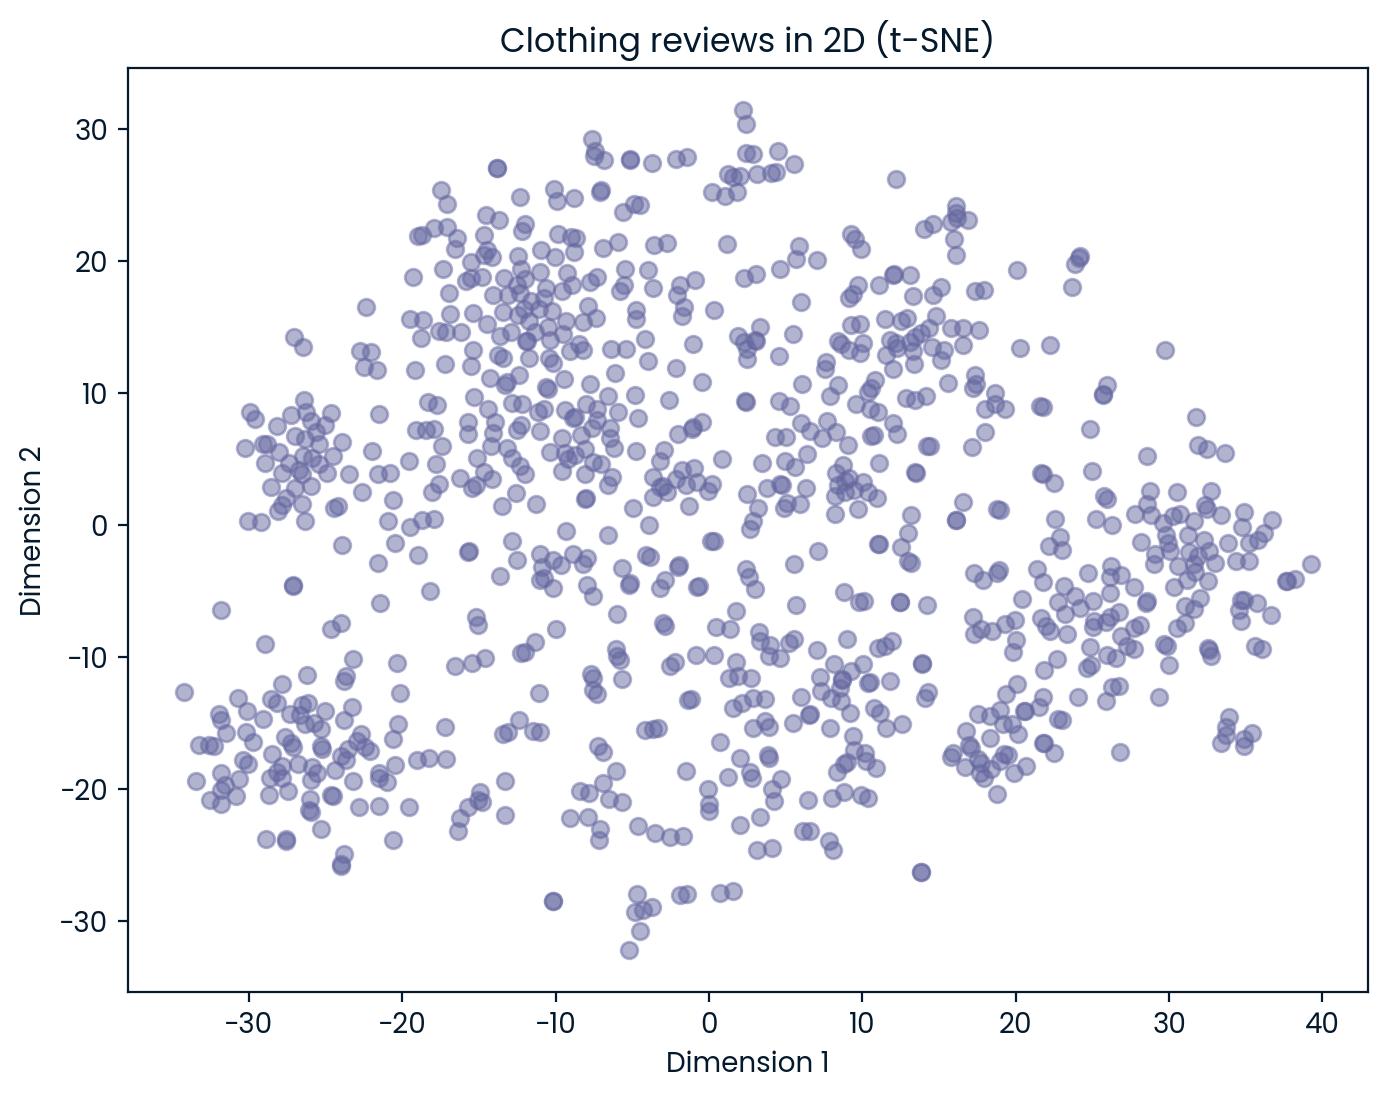

In [47]:
# Celda 3: reducir a dos dimensiones y dibujar el gráfico.

perplexity = min(30, len(embeddings) - 1)
tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    random_state=42
)
embeddings_2d = tsne.fit_transform(np.array(embeddings))

plt.figure(figsize=(8, 6))
plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], alpha=0.5)
plt.title("Clothing reviews in 2D (t-SNE)")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.show()


In [48]:
# Celda 4: identificar las tres reseñas más cercanas a cada tema.

def cosine_similarity(a, b):
    a, b = np.array(a), np.array(b)
    return float(
        np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    )

topics = ["quality", "fit", "style", "comfort"]
topic_embeddings = embed_fn(topics)

for topic, t_emb in zip(topics, topic_embeddings):
    scores = [cosine_similarity(t_emb, e) for e in embeddings]
    top_idx = np.argsort(scores)[-3:][::-1]
    print(f"\n== {topic} ==")
    for i in top_idx:
        print("-", texts[i])



== quality ==
- I bought this and like other reviews, agree that the quality probably could be better, but i still love it enough to keep. the buckle fell apart, but i was able to fix it and the zipper seems a little weak. it has pilled, but the fabric is textured, so i didn't even notice until i read the other reviews and then looked back at my jacket.  it is a perfect medium coat for 40's & 50's before i am ready to bust out my ugly down north face for winter.  i get compliments every time i wear it!  love!!
- Top of the line! very well made and on sale to boot. i love the style and received a compliment from my sister when i wore it. i love the layered look.
- I love the rich deep color and the style but once again this brand runs really small in the waist. i am normally a 8/10 in retailer skirts and the size 10 was tight at the waist enough so i could not button it and feel comfortable. the quality is ok, something i feel i would see at another type of discount store. for me this 

In [ ]:
# Celda 5: buscar las tres reseñas similares a la indicada y guardar el resultado en «most_similar_reviews».

def find_most_similar(review_text, n=3):
    query_emb = embed_fn([review_text])[0]
    scores = [cosine_similarity(query_emb, e) for e in embeddings]
    top_idx = np.argsort(scores)[::-1]
    results = [texts[i] for i in top_idx]
    return results[:n]

most_similar_reviews = find_most_similar(
    "Absolutely wonderful - silky and sexy and comfortable"
)
most_similar_reviews

['Very comfortable and versatile. got lots of compliments.',
 'Very cute, very comfortable. for me aesthetics and comfort must go hand in hand. this dress fits the bill.',
 'Cute and comfortable! i loved the colors and how soft the shirt is!']